# Crystal-field tomography, 2D toy, smooth orientation field
The targets are the mean potential and the crystallinity; orientation is a nuisance. Every tenth tilt is held out. Inversions come from `run_smooth.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

import sim2d

## Data
Twinned particle of one phase with an amorphous cap at the same density, and the same particle without the cap.

In [2]:
sim2d.main("fewAm")
sim2d.main("fewA")
sims = {kind: np.load(f"runs/sim_{kind}.npz") for kind in ["fewAm", "fewA"]}
runs = {
    "fewAm": {
        "mean potential only": "sm_fewAm_meanonly",
        "smooth orientation": "sm_fewAm_learned",
        "smooth + sharp + diffuse": "sm_fewAm_full",
        "same, true lattice (diagnostic)": "sm_fewAm_full_truelat",
        "same + L1 on crystallinity (diagnostic)": "sm_fewAm_full_truelat_c01",
    },
    "fewA": {
        "mean potential only": "sm_fewA_meanonly",
        "smooth orientation": "sm_fewA_learned",
        "smooth, true lattice (diagnostic)": "sm_fewA_truelat",
    },
}
res = {kind: {name: np.load(f"runs/{f}.npz") for name, f in r.items()} for kind, r in runs.items()}

fewAm: 3011 atoms, 3 grains, 40 Friedel pairs, multislice 1.6 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewAm.npz


fewA: 3025 atoms, 3 grains, 60 Friedel pairs, multislice 1.6 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_2d/runs/sim_fewA.npz


## Scores
Image error normalised by the data variance on train and held-out tilts. Density correlation with the true mean potential. Mean crystallinity in the crystal, the amorphous cap and outside the particle.

In [3]:
for kind, d in sims.items():
    data = d["I_coarse"]
    c = slice(data.shape[1] // 2 - 70, data.shape[1] // 2 + 70)
    var = data[:, c].var()
    held = np.arange(5, len(data), 10)
    train = np.setdiff1d(np.arange(len(data)), held)
    part = d["occ"].sum(0) > 0.5
    cryst = d["cryst"]
    print(kind)
    for name, r in res[kind].items():
        e = ((r["pred"] - data)[:, c] ** 2).mean(1) / var
        line = f"  {name:42s} train {e[train].mean():.3f}  held-out {e[held].mean():.3f}"
        line += f"  density corr {np.corrcoef(r['vbar'].ravel(), d['vbar'].ravel())[0, 1]:.3f}"
        if name != "mean potential only":
            cr = r["cryst"]
            amorph = part & (cryst < 0.5)
            line += f"  crystallinity: crystal {cr[part & (cryst > 0.5)].mean():.2f}"
            line += f", amorphous {cr[amorph].mean():.2f}" if amorph.any() else ""
            line += f", outside {cr[~part].mean():.2f}"
        print(line)

fewAm
  mean potential only                        train 0.516  held-out 0.844  density corr 0.826
  smooth orientation                         train 0.220  held-out 0.741  density corr 0.812  crystallinity: crystal 1.00, amorphous 1.00, outside 0.24
  smooth + sharp + diffuse                   train 0.339  held-out 0.800  density corr 0.831  crystallinity: crystal 0.85, amorphous 0.97, outside 0.13
  same, true lattice (diagnostic)            train 0.249  held-out 0.622  density corr 0.843  crystallinity: crystal 0.88, amorphous 0.95, outside 0.13
  same + L1 on crystallinity (diagnostic)    train 0.361  held-out 0.786  density corr 0.834  crystallinity: crystal 0.23, amorphous 0.21, outside 0.01
fewA
  mean potential only                        train 0.694  held-out 1.133  density corr 0.846
  smooth orientation                         train 0.271  held-out 1.261  density corr 0.812  crystallinity: crystal 1.00, outside 0.30
  smooth, true lattice (diagnostic)          train 0.254  h

## All tilts, amorphous cap

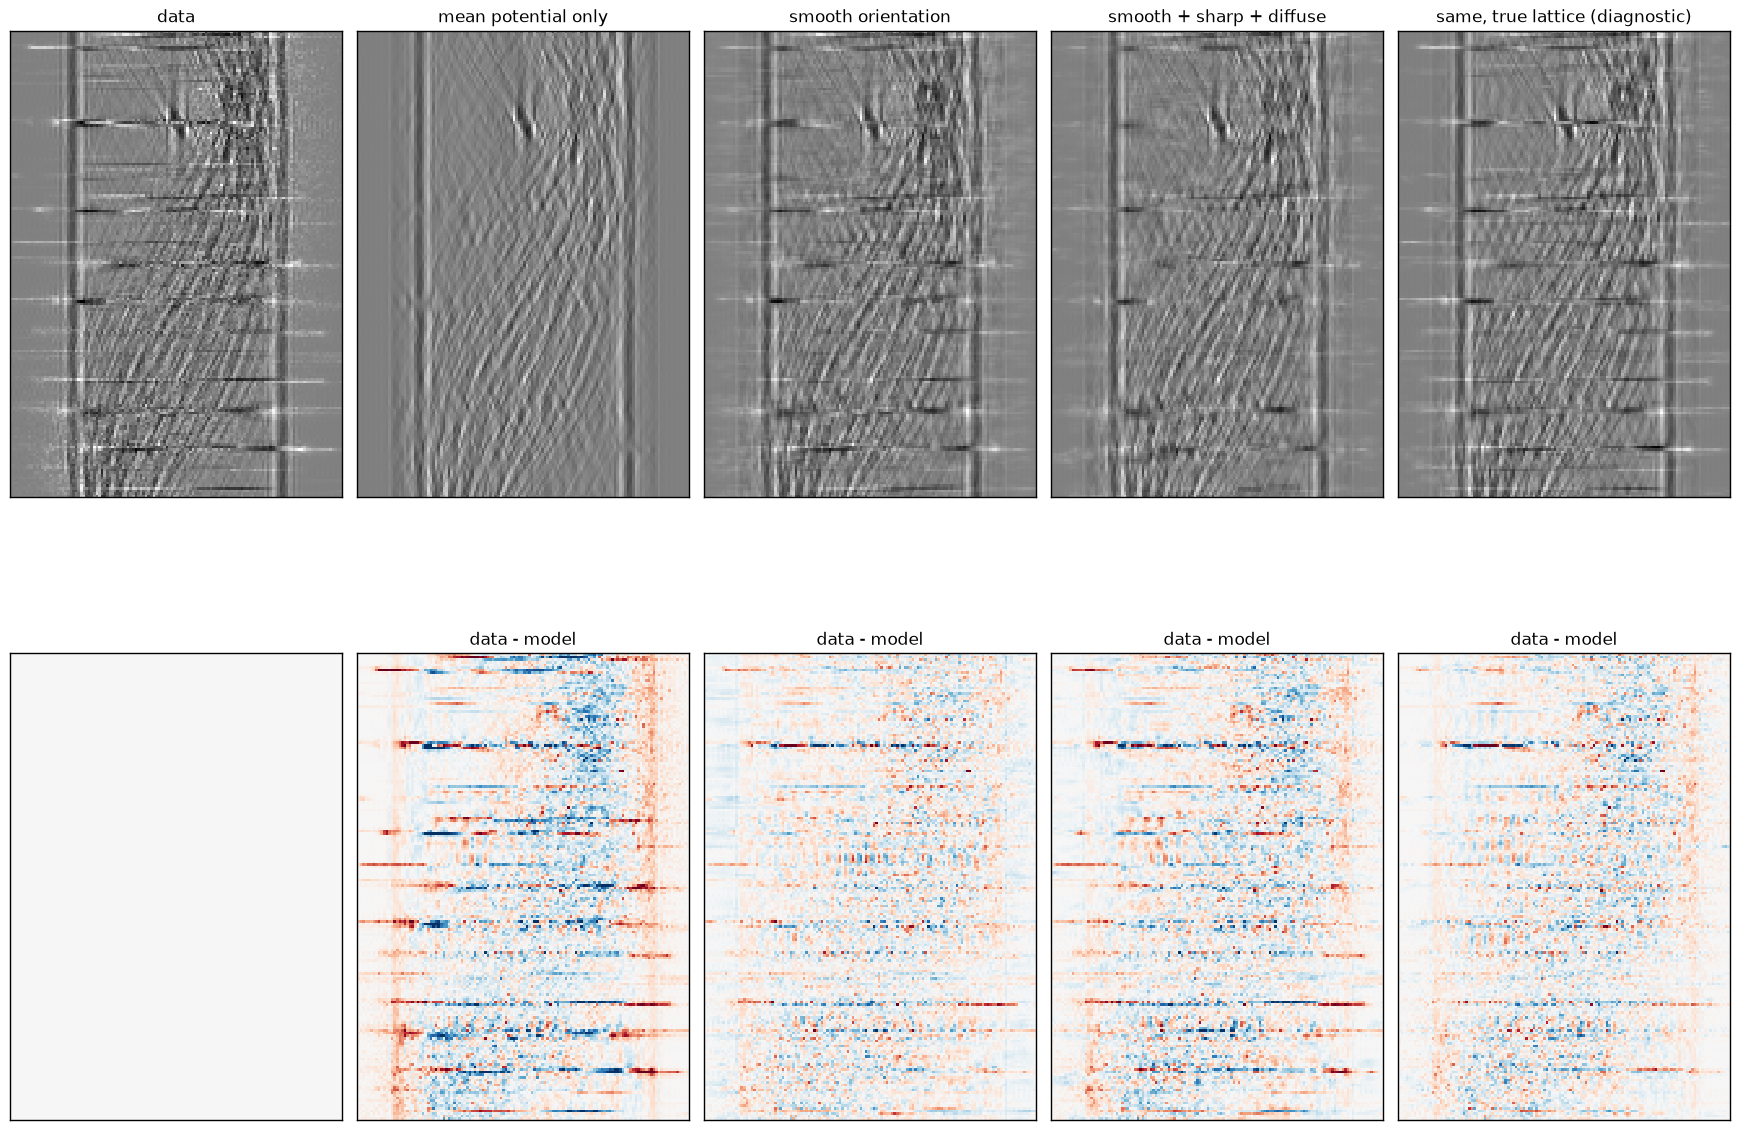

In [4]:
d = sims["fewAm"]
r = res["fewAm"]
data = d["I_coarse"]
crop = slice(data.shape[1] // 2 - 64, data.shape[1] // 2 + 64)
held = np.arange(5, len(data), 10)
names = list(r)[:4]
norm_int = {"interval_type": "manual", "vmin": 0.2, "vmax": 1.8}
norm_diff = {"interval_type": "centered", "half_range": 0.5}
show_2d(
    [
        [data[:, crop]] + [r[n]["pred"][:, crop] for n in names],
        [np.zeros_like(data[:, crop])] + [data[:, crop] - r[n]["pred"][:, crop] for n in names],
    ],
    norm=[[norm_int] * 5, [norm_diff] * 5],
    cmap=[["gray"] * 5, ["RdBu_r"] * 5],
    title=[["data"] + names, [""] + ["data - model"] * 4],
    axsize=(3.5, 7),
);

## Held-out tilts, amorphous cap
Each held-out tilt is drawn six rows tall.

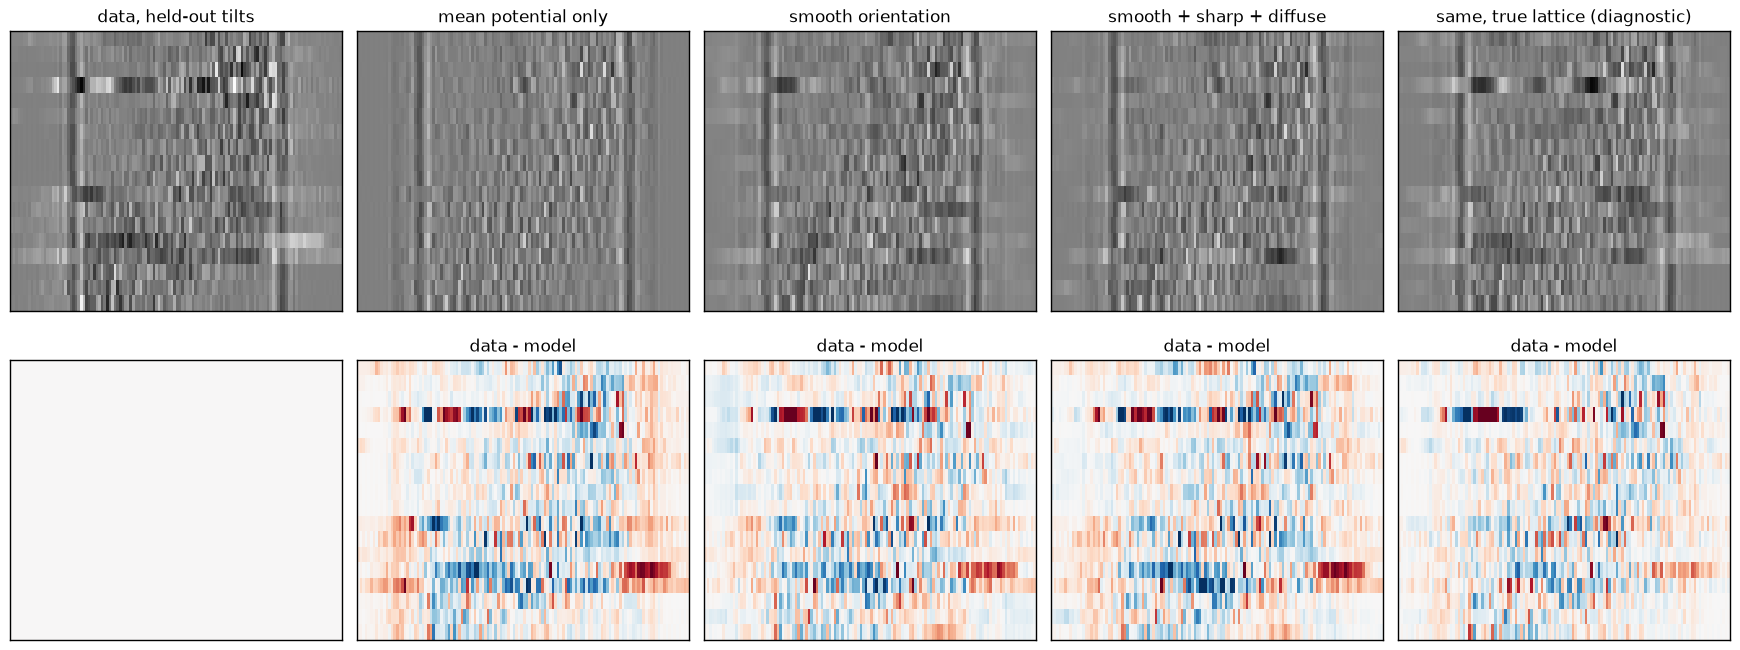

In [5]:
tall = lambda a: np.repeat(a[held][:, crop], 6, axis=0)
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in names],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in names],
    ],
    norm=[[norm_int] * 5, [norm_diff] * 5],
    cmap=[["gray"] * 5, ["RdBu_r"] * 5],
    title=[["data, held-out tilts"] + names, [""] + ["data - model"] * 4],
    axsize=(3.5, 3.5),
);

## Mean potential and crystallinity, amorphous cap

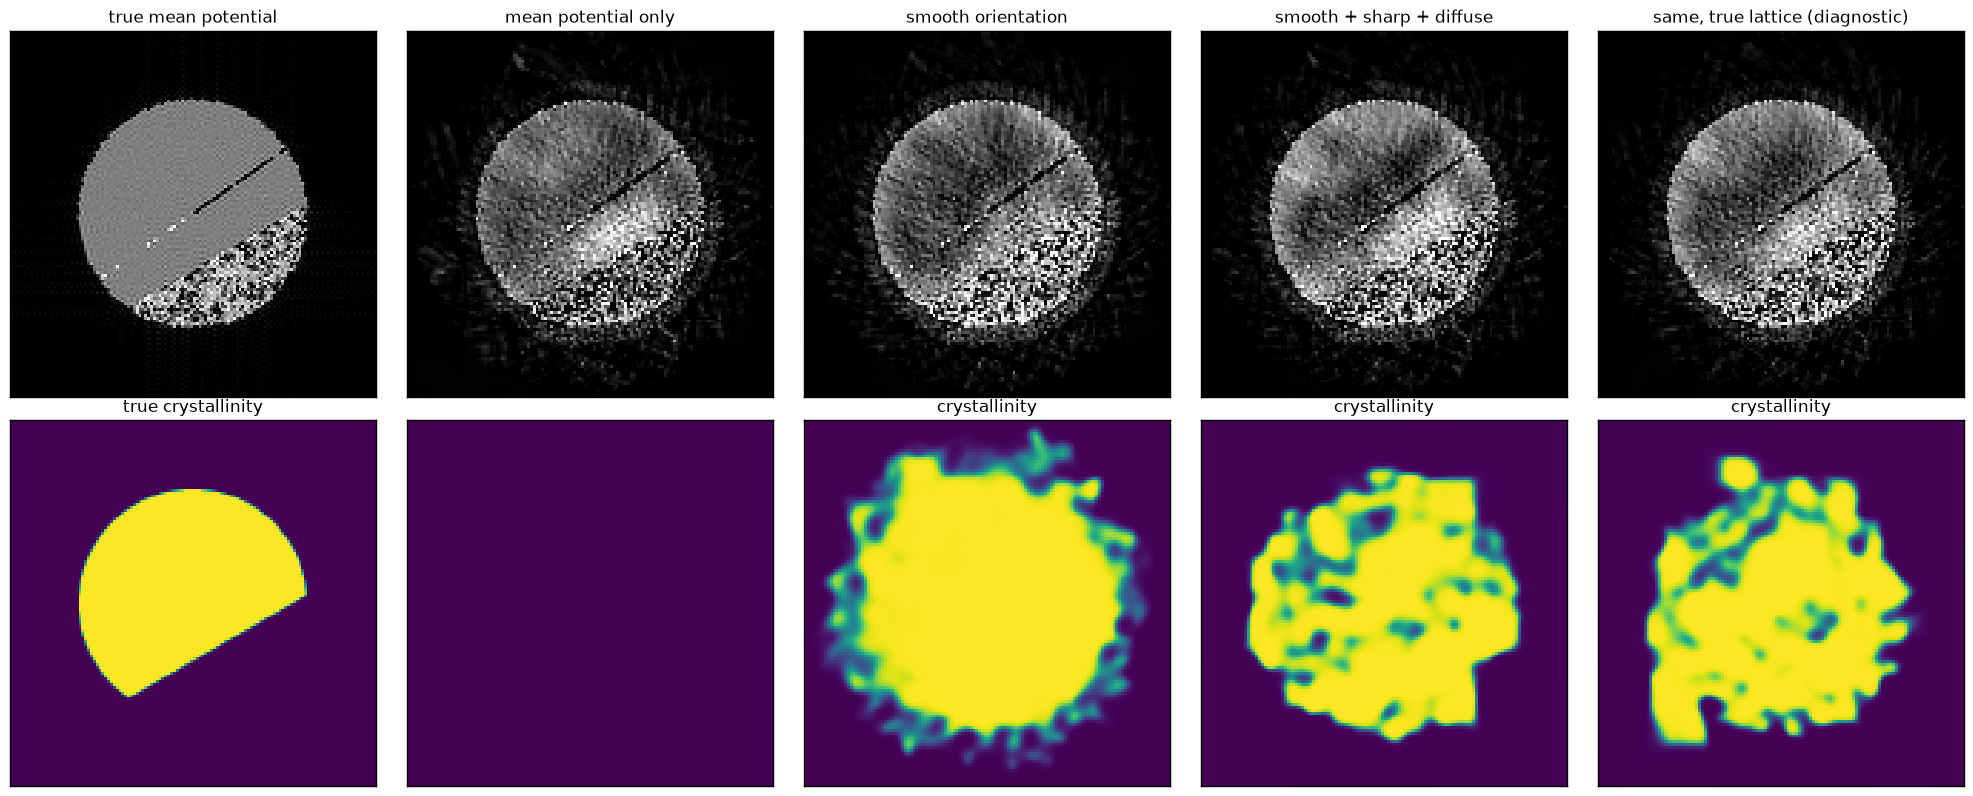

In [6]:
show_2d(
    [
        [np.flipud(d["vbar"].T)] + [np.flipud(r[n]["vbar"].T) for n in names],
        [np.flipud(d["cryst"].T), np.zeros_like(d["cryst"])] + [np.flipud(r[n]["cryst"].T) for n in names[1:]],
    ],
    norm=[[{"interval_type": "manual", "vmin": 0.0, "vmax": 0.04}] * 5, [{"interval_type": "manual", "vmin": 0.0, "vmax": 1.0}] * 5],
    cmap=[["gray"] * 5, ["viridis"] * 5],
    title=[
        ["true mean potential"] + names,
        ["true crystallinity", ""] + ["crystallinity"] * 3,
    ],
);

## Held-out tilts, no amorphous cap
Each held-out tilt is drawn six rows tall.

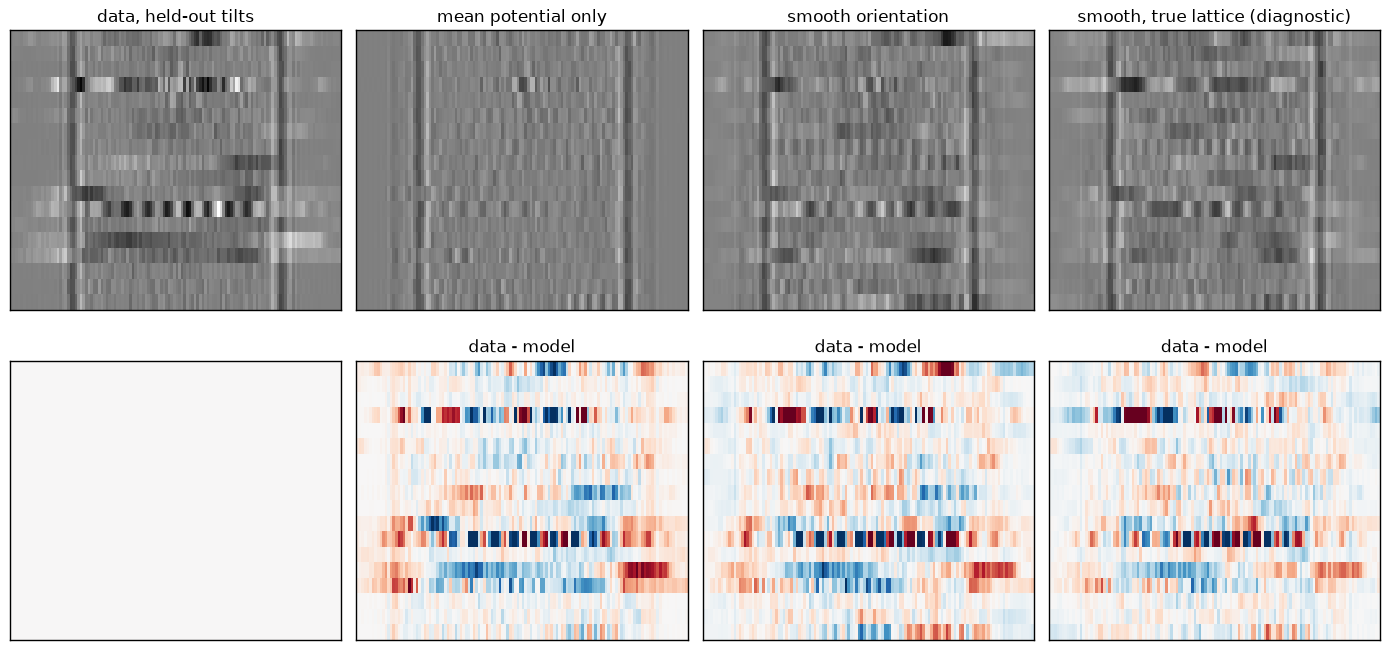

In [7]:
d = sims["fewA"]
r = res["fewA"]
data = d["I_coarse"]
names = list(r)
tall = lambda a: np.repeat(a[held][:, crop], 6, axis=0)
show_2d(
    [
        [tall(data)] + [tall(r[n]["pred"]) for n in names],
        [np.zeros_like(tall(data))] + [tall(data) - tall(r[n]["pred"]) for n in names],
    ],
    norm=[[norm_int] * 4, [norm_diff] * 4],
    cmap=[["gray"] * 4, ["RdBu_r"] * 4],
    title=[["data, held-out tilts"] + names, [""] + ["data - model"] * 3],
    axsize=(3.5, 3.5),
);